# 実験結果の分析用ノートブック

MovieLens 1M の保存済み NeuMF-pre を使用する。
評価は全3,706作品から各ユーザーの学習済み作品を除いた候補を対象とする。推薦件数は10件、seed は42。


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib import ticker
import numpy as np
import pandas as pd
import torch
import yaml
from scipy.special import expit
from IPython.display import Markdown, display

%matplotlib inline
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'papers/recsys/2017_ncf/ncf_reproduction').is_dir())
project = root / 'papers/recsys/2017_ncf'
sys.path.insert(0, str(project))
from ncf_reproduction.data import load_data
from ncf_reproduction.model import NeuMF
from popularity_reranking.reranking import (
    interaction_groups, profile_distribution, rerank_smooth,
    select_operating_points, top_indices,
)

run_dir = project / 'outputs/fixed-val-20261122-154335'
docs_dir = project / 'docs'
docs_dir.mkdir(exist_ok=True)


In [2]:
@torch.inference_mode()
def predict_catalog(model, user_num, catalog, seen, batch_size=8192):
    """全作品を推論し、ユーザーごとの学習済み作品だけを候補から除く。"""
    result = np.empty((user_num, len(catalog)), dtype=np.float64)
    total = result.size
    for start in range(0, total, batch_size):
        positions = np.arange(start, min(start + batch_size, total))
        users = positions // len(catalog)
        items = catalog[positions % len(catalog)]
        logits = model(torch.from_numpy(users), torch.from_numpy(items)).cpu().numpy()
        result.ravel()[positions] = expit(logits.astype(float))
    # val・test の作品も通常の候補として扱い、正解を上位候補に強制挿入しない。
    users, items = seen.nonzero()
    column = np.full(seen.shape[1], -1, dtype=int)
    column[catalog] = np.arange(len(catalog))
    valid = column[items] >= 0
    result[users[valid], column[items[valid]]] = -np.inf
    return result


def rank(strength):
    positions = rerank_smooth(
        initial_relevance, groups[initial], preferences, strength, k=10
    )
    return np.take_along_axis(initial, positions, axis=1)


def evaluate(recommended, split):
    """正解率と低人気作品の推薦枠・カバレッジを同じ推薦リストから計算する。"""
    matches = recommended == positives[split][:, None]
    hit = matches.any(axis=1)
    ndcg = np.where(hit, 1 / np.log2(matches.argmax(axis=1) + 2), 0)
    unique_tail = int((groups[np.unique(recommended)] == 1).sum())
    return {
        "hr": hit.mean(),
        "ndcg": ndcg.mean(),
        "aplt": (groups[recommended] == 1).mean(),
        "unique_tail_items": unique_tail,
        "tail_coverage": unique_tail / int((groups == 1).sum()),
    }

In [3]:
# 元の学習データと保存済みモデルを読み込む。再学習は行わない。
cfg = yaml.safe_load((run_dir / "NeuMF-pre/.hydra/config.yaml").read_text())
seed = int(cfg["seed"])
torch.set_num_threads(min(4, torch.get_num_threads()))
torch.manual_seed(seed)
train_rows, val_rows, test_rows, user_num, item_num, train_mat = load_data(
    project, seed
)
train = np.asarray(train_rows, dtype=np.int64)
seen = train_mat.tocsr()
popularity = np.bincount(train[:, 1], minlength=item_num)
groups, _ = interaction_groups(popularity, [0.8])
preferences = profile_distribution(train, groups, user_num, 2)
positives = {
    split: np.asarray(rows, dtype=np.int64).reshape(user_num, 100, 2)[:, 0, 1]
    for split, rows in [("val", val_rows), ("test", test_rows)]
}
for items in positives.values():
    assert not np.asarray(seen[np.arange(user_num), items]).any()
settings = cfg["model"]
model = NeuMF(
    user_num,
    item_num,
    settings["factor_num"],
    settings["num_layers"],
    settings["dropout"],
)
checkpoint = torch.load(
    run_dir / "NeuMF-pre/checkpoint.pt", map_location="cpu", weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(f"{user_num:,}ユーザー × {item_num:,}作品を推論中…")
catalog = np.arange(item_num)
relevance = predict_catalog(model, user_num, catalog, seen)
initial = top_indices(relevance, 100)
initial_relevance = np.take_along_axis(relevance, initial, axis=1)
baseline = initial[:, :10]
base = evaluate(baseline, "test")
print("推論完了")

6,040ユーザー × 3,706作品を推論中…
推論完了


## 人気度の偏りの可視化 

人気度は学習データ内の出現回数で定義する。累積出現回数の約80%を占める作品を「人気作品」、残りを「低人気作品」とする。
ユーザーの履歴では低人気作品が平均15.88%を占める一方、NeuMF の推薦10件では3.16%にとどまる。


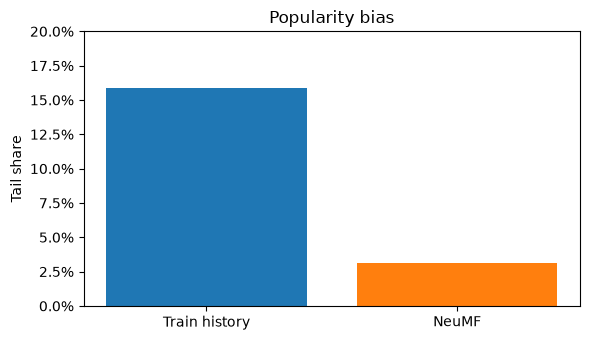

In [4]:
history_tail = preferences[:, 1].mean()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(["Train history", "NeuMF"], [history_tail, base["aplt"]], color=["C0", "C1"])
ax.set(title="Popularity bias", ylabel="Tail share", ylim=(0, 0.2))
ax.yaxis.set_major_formatter(ticker.PercentFormatter(1))
fig.tight_layout()
fig.savefig(docs_dir / "popularity_bias.png", dpi=160, bbox_inches="tight")
plt.show()

## 2. Smooth xQuAD で推薦の構成を調整

NeuMF の関連度上位100件から、次のスコアが高い作品を1件ずつ選び、10件の推薦を作る。

**元の関連度 ＋ λ × 履歴でのカテゴリ比率 × 推薦済みの構成に応じたボーナス**

履歴に含まれる割合が高いのに、推薦済みのリストに十分含まれていないカテゴリへボーナスを付ける。
モデルを再学習せず、ユーザーごとの履歴を考慮して低人気作品の推薦機会を増やす。

λ は val の HR・NDCG の低下をそれぞれ絶対値0.005以内に抑えた候補から、低人気作品の推薦枠が最大の値を選ぶ。
出典：[Abdollahpouri et al., FLAIRS 2019](https://cdn.aaai.org/ocs/18199/18199-78818-1-PB.pdf)。


In [5]:
# モデルのハイパーパラメータは固定し、後処理の係数だけを val で選ぶ。
grid = [
    0.0,
    0.001,
    0.003,
    0.01,
    0.03,
    0.1,
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
    0.99,
    1.0,
]
sweep = pd.DataFrame(
    [
        {"method": "Smooth", "strength": strength, **evaluate(rank(strength), "val")}
        for strength in grid
    ]
)
selected = select_operating_points(sweep)
strength = float(selected.iloc[0].strength)
print(f"val で選んだ補正係数：λ = {strength:g}")

val で選んだ補正係数：λ = 0.8


## 3. 改善の可視化する

同じモデル・同じ候補で、低人気作品の推薦枠と推薦された作品数を比較する。
精度も併記し、推薦機会の拡大と全体精度の変化を確認する。


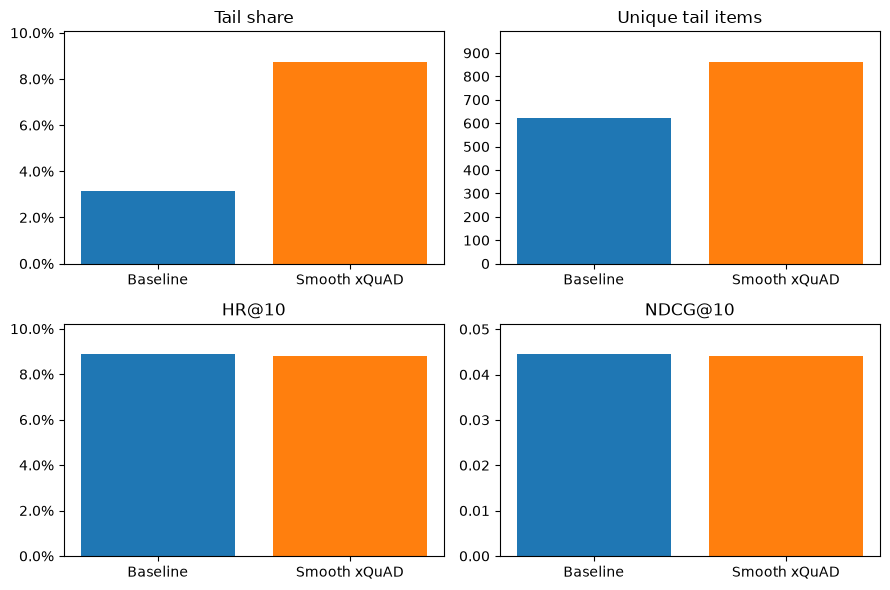

低人気作品の推薦枠: 3.16% → 8.75%
推薦された低人気作品: 622作品 → 863作品
全体の HR@10: 8.89% → 8.81%


In [8]:
recommended = rank(strength)
assert not (np.diff(np.sort(recommended, axis=1), axis=1) == 0).any()
assert not np.asarray(
    seen[np.repeat(np.arange(user_num), 10), recommended.ravel()]
).any()
smooth = evaluate(recommended, "test")

fig, axes = plt.subplots(2, 2, figsize=(9, 6))
plots = [
    ("aplt", "Tail share"),
    ("unique_tail_items", "Unique tail items"),
    ("hr", "HR@10"),
    ("ndcg", "NDCG@10"),
]
for ax, (metric, title) in zip(axes.ravel(), plots):
    values = [base[metric], smooth[metric]]
    ax.bar(["Baseline", "Smooth xQuAD"], values, color=["C0", "C1"])
    ax.set(title=title, ylim=(0, max(values) * 1.15))
    if metric in ["aplt", "hr"]:
        ax.yaxis.set_major_formatter(ticker.PercentFormatter(1))
    elif metric == "unique_tail_items":
        ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))
fig.tight_layout()
fig.savefig(docs_dir / "reranking_results.png", dpi=160, bbox_inches="tight")
plt.show()
print(f"低人気作品の推薦枠: {base['aplt']:.2%} → {smooth['aplt']:.2%}")
print(
    f"推薦された低人気作品: {base['unique_tail_items']:,}作品 → {smooth['unique_tail_items']:,}作品"
)
print(f"全体の HR@10: {base['hr']:.2%} → {smooth['hr']:.2%}")

低人気作品の推薦枠は 3.16% → 8.75%、推薦された低人気作品は 622 → 863作品 に増えた。全体の HR@10 は 8.89% → 8.81%。